## 1. Definición del problema para el analisis supervisado

**Aprendizaje supervisado:** el modelo aprende a partir de ejemplos en los que ya conocemos la respuesta correcta (la *variable objetivo*). Con esos ejemplos encuentra patrones entre las *variables de entrada* y la respuesta, para después predecir casos nuevos cuya respuesta aún no conocemos.

- **Caso práctico:** partidos de la NFL (fuente: nflverse, licencia CC BY 4.0).
- **Pregunta:** antes de que se juegue un partido, ¿ganará el equipo local?
- **Tipo de problema:** clasificación binaria, porque la respuesta es una categoría (sí o no) y no un número.
- **Variable objetivo:** `gana_local` = 1 si los puntos del local superan a los del visitante; 0 en otro caso.
- **Variables de entrada:** se construirán solo con información disponible *antes* del partido (forma reciente, días de descanso, etc.).
- **Complementario (regresión):** predecir el diferencial de puntos, que es un número.

In [1]:
# Celda 1: Pasos de verficacion de librerías y conexion al venv creado.
import sys
import pandas as pd
import sklearn
import matplotlib

#Print para la Verificacion de el traceback route
print("Python en uso:", sys.executable)

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib:", matplotlib.__version__)

# Dataset público de partidos de la NFL (nflverse / Lee Sharpe)
URL = "https://github.com/nflverse/nfldata/raw/master/data/games.csv"
juegos = pd.read_csv(URL)
juegos.to_csv("../data/raw/games_original.csv", index=False)

print("Filas y columnas:", juegos.shape)
juegos.head()

Python en uso: /Users/diegoperez/Documents/Documentos - MacBook Air de Diego/Codigos Personales/Data Models/.venv/bin/python
Python: 3.12.1
pandas: 2.3.3
scikit-learn: 1.9.1
matplotlib: 3.10.3
Filas y columnas: (7548, 46)


,game_id,season,game_type,week,gameday,weekday,gametime,away_team,away_score,home_team,...,wind,away_qb_id,home_qb_id,away_qb_name,home_qb_name,away_coach,home_coach,referee,stadium_id,stadium
0,1999_01_MIN_ATL,1999,REG,1,1999-09-12,Sunday,NaN,MIN,17.0,ATL,...,NaN,00-0003761,00-0002876,Randall Cunningham,Chris Chandler,Dennis Green,Dan Reeves,Gerry Austin,ATL00,Georgia Dome
1,1999_01_KC_CHI,1999,REG,1,1999-09-12,Sunday,NaN,KC,17.0,CHI,...,12.0,00-0006300,00-0010560,Elvis Grbac,Shane Matthews,Gunther Cunningham,Dick Jauron,Phil Luckett,CHI98,Soldier Field
2,1999_01_PIT_CLE,1999,REG,1,1999-09-12,Sunday,NaN,PIT,43.0,CLE,...,12.0,00-0015700,00-0004230,Kordell Stewart,Ty Detmer,Bill Cowher,Chris Palmer,Bob McElwee,CLE00,Cleveland Browns Stadium
3,1999_01_OAK_GB,1999,REG,1,1999-09-12,Sunday,NaN,OAK,24.0,GB,...,10.0,00-0005741,00-0005106,Rich Gannon,Brett Favre,Jon Gruden,Ray Rhodes,Tony Corrente,GNB00,Lambeau Field
4,1999_01_BUF_IND,1999,REG,1,1999-09-12,Sunday,NaN,BUF,14.0,IND,...,NaN,00-0005363,00-0010346,Doug Flutie,Peyton Manning,Wade Phillips,Jim Mora,Ron Blum,IND99,RCA Dome


## 2. Carga y exploración inicial

Cargamos la copia original del dataset que guardamos en `data/raw/`. Primero revisamos su tamaño, qué columnas tiene y de qué tipo es cada una.

In [2]:
import pandas as pd

juegos = pd.read_csv("../data/raw/games_original.csv")

print("Filas y columnas:", juegos.shape)
juegos.info() 

Filas y columnas: (7548, 46)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7548 entries, 0 to 7547
Data columns (total 46 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   game_id           7548 non-null   object 
 1   season            7548 non-null   int64  
 2   game_type         7548 non-null   object 
 3   week              7548 non-null   int64  
 4   gameday           7548 non-null   object 
 5   weekday           7548 non-null   object 
 6   gametime          7289 non-null   object 
 7   away_team         7548 non-null   object 
 8   away_score        7427 non-null   float64
 9   home_team         7548 non-null   object 
 10  home_score        7427 non-null   float64
 11  location          7548 non-null   object 
 12  result            7427 non-null   float64
 13  total             7427 non-null   float64
 14  overtime          7427 non-null   float64
 15  old_game_id       7548 non-null   int64  
 16  gsis         

### Partidos por temporada y tipo

Revisamos qué temporadas cubre el dataset y qué tipos de partido hay (temporada regular o playoffs). También contamos cuántos partidos todavía no tienen marcador, es decir, que aún no se han jugado.

In [3]:
# Celda 3: Una vez que tenmos las datos importados calculamos visualizamos el rango de temporadas, tipos de partido y partidos sin marcador
print("Temporadas:", juegos["season"].min(), "a", juegos["season"].max())

# REG = temporada regular; WC, DIV, CON, SB = rondas de playoffs
print(juegos["game_type"].value_counts())

# Un partido sin puntos registrados todavía no se juega
sin_marcador = juegos["home_score"].isna().sum()
print("Partidos sin marcador (aún no jugados):", sin_marcador)

Temporadas: 1999 a 2026
game_type
REG    7239
WC      120
DIV     108
CON      54
SB       27
Name: count, dtype: int64
Partidos sin marcador (aún no jugados): 121


En donde la existen 7239 partido de temporada regular hasta la fecha de hoy: 120 de Wild Cards: 108 del Divisional Round: 54 campeonatos de conferencia y 27 Super Bowls

### Se plantea una metrica ¿Qué tan seguido gana el local?

Revisamos cómo se reparte la variable objetivo. Esto nos dice si las clases están balanceadas y nos da la primera **línea base**: el porcentaje de aciertos que obtendríamos si siempre predijéramos "gana local". También revisamos los empates y los partidos en campo neutral, donde en realidad no hay local.

In [4]:
# Celda 4: distribución del resultado local vs visitante (solo partidos ya jugados)
jugados = juegos.dropna(subset=["home_score", "away_score"])

#jugadas es nuestra variable contable que va a irse sumando dependindo de los resultados a favor
gana_local = (jugados["home_score"] > jugados["away_score"])
empates = (jugados["home_score"] == jugados["away_score"]).sum()

print(f"El local gana el {gana_local.mean():.1%} de los partidos")
print("Empates:", empates)

# 'location' indica si el partido fue en casa del local o en sede neutral
print(jugados["location"].value_counts())

El local gana el 56.1% de los partidos
Empates: 16
location
Home       7325
Neutral     102
Name: count, dtype: int64


## 3. Limpieza y calidad de datos (Temas vistos en la Unidad 2)

Seleccionamos solo las columnas útiles para el problema. Descartamos:
- Identificadores de otros sistemas (`old_game_id`, `gsis`, `espn`, `pfr`, etc.), porque no aportan información.
- Columnas de apuestas (`spread_line`, momios, `total_line`), porque están fuera del alcance del proyecto.
- Columnas con muchos nulos o poco relevantes para esta primera versión (clima, árbitro, entrenadores, mariscales de campo).

In [5]:
# Celda 5: quedarnos solo con las columnas relevantes de todas las importadas
columnas = [
    "game_id", "season", "game_type", "week", "gameday",
    "home_team", "away_team", "home_score", "away_score",
    "location", "home_rest", "away_rest", "div_game", "roof", "surface",
]
df = juegos[columnas].copy()

print("Columnas antes:", juegos.shape[1], "| después:", df.shape[1])
df.head()

Columnas antes: 46 | después: 15


,game_id,season,game_type,week,gameday,home_team,away_team,home_score,away_score,location,home_rest,away_rest,div_game,roof,surface
0,1999_01_MIN_ATL,1999,REG,1,1999-09-12,ATL,MIN,14.0,17.0,Home,7,7,0,dome,astroturf
1,1999_01_KC_CHI,1999,REG,1,1999-09-12,CHI,KC,20.0,17.0,Home,7,7,0,outdoors,grass
2,1999_01_PIT_CLE,1999,REG,1,1999-09-12,CLE,PIT,0.0,43.0,Home,7,7,1,outdoors,grass
3,1999_01_OAK_GB,1999,REG,1,1999-09-12,GB,OAK,28.0,24.0,Home,7,7,0,outdoors,grass
4,1999_01_BUF_IND,1999,REG,1,1999-09-12,IND,BUF,31.0,14.0,Home,7,7,1,dome,astroturf


### Tipos de dato, duplicados y nulos

- Convertimos `gameday` de texto a fecha real (`datetime`) para poder ordenar y comparar fechas.
- Verificamos que no haya partidos duplicados usando `game_id`, que debe ser único.
- Contamos los nulos por columna para decidir qué hacer con ellos.

In [6]:
# Celda 6: tipos, duplicados y nulos
df["gameday"] = pd.to_datetime(df["gameday"])

duplicados = df["game_id"].duplicated().sum()
print("Partidos duplicados:", duplicados)

print("\nNulos por columna:")
print(df.isna().sum()[df.isna().sum() > 0])

Partidos duplicados: 0

Nulos por columna:
home_score    121
away_score    121
roof           18
surface       130
dtype: int64


### Uso del metodo de Normalización de nombres de equipos que cambiaron de nombre durante los años 1999-2026

Algunas franquicias cambiaron de ciudad y de abreviatura durante el periodo de los datos:
- Oakland Raiders (`OAK`) → Las Vegas Raiders (`LV`) en 2020
- San Diego Chargers (`SD`) → Los Angeles Chargers (`LAC`) en 2017
- St. Louis Rams (`STL`) → Los Angeles Rams (`LA`) en 2016

Si no las unificamos, el modelo trataría a un mismo equipo como si fueran dos distintos y partiría su historial. Es la misma regla de calidad que aplicaría el ETL del Data Warehouse para `DimEquipo`.

In [7]:
# Celda 7: Se unifican las abreviaturas de franquicias mudadas
mapa_equipos = {"OAK": "LV", "SD": "LAC", "STL": "LA"}

for col in ["home_team", "away_team"]:
    df[col] = df[col].replace(mapa_equipos)

print("Equipos distintos:", df["home_team"].nunique())
print(sorted(df["home_team"].unique()))

Equipos distintos: 32
['ARI', 'ATL', 'BAL', 'BUF', 'CAR', 'CHI', 'CIN', 'CLE', 'DAL', 'DEN', 'DET', 'GB', 'HOU', 'IND', 'JAX', 'KC', 'LA', 'LAC', 'LV', 'MIA', 'MIN', 'NE', 'NO', 'NYG', 'NYJ', 'PHI', 'PIT', 'SEA', 'SF', 'TB', 'TEN', 'WAS']


### Variable objetivo y guardado del dataset limpio

- Nos quedamos solo con partidos ya jugados, porque solo de ellos conocemos la respuesta. Los que aún no se juegan se guardan aparte: más adelante podrían servir para hacer predicciones reales.
- Creamos la variable objetivo `gana_local` (1 = gana el local, 0 = pierde o empata) y la variable `diferencial` (puntos del local menos puntos del visitante) para la regresión complementaria.
- Ordenamos por fecha, porque eso será clave en la ingeniería de variables y en la partición.
- Guardamos el resultado en `data/clean/`.

In [8]:
# Celda 8: crear las variables objetivo y guardar el dataset limpio
por_jugar = df[df["home_score"].isna()].copy()
df = df.dropna(subset=["home_score", "away_score"]).copy()

df["gana_local"] = (df["home_score"] > df["away_score"]).astype(int)  # True/False -> 1/0
df["diferencial"] = df["home_score"] - df["away_score"]

df = df.sort_values("gameday").reset_index(drop=True)

df.to_csv("../data/clean/games_clean.csv", index=False)
por_jugar.to_csv("../data/clean/games_por_jugar.csv", index=False)

print("Partidos jugados (dataset limpio):", len(df))
print("Partidos por jugar:", len(por_jugar))
print(df["gana_local"].value_counts(normalize=True).round(3))

Partidos jugados (dataset limpio): 7427
Partidos por jugar: 121
gana_local
1    0.561
0    0.439
Name: proportion, dtype: float64


## 4. Ingeniería de variables

### Tabla equipo-partido

Transformamos cada partido en dos filas, una por equipo (local y visitante). Así cada equipo tiene una línea de tiempo con su historial completo, sin importar si jugó en casa o de visita. Sobre esta tabla calcularemos su forma reciente.

In [9]:
# Celda 9: desdoblar cada partido en dos filas (una por equipo)
base = ["game_id", "gameday", "season"]

local = df[base].copy()
local["equipo"], local["rival"], local["es_local"] = df["home_team"], df["away_team"], 1
local["pts_favor"], local["pts_contra"] = df["home_score"], df["away_score"]

visita = df[base].copy()
visita["equipo"], visita["rival"], visita["es_local"] = df["away_team"], df["home_team"], 0
visita["pts_favor"], visita["pts_contra"] = df["away_score"], df["home_score"]

eq = pd.concat([local, visita], ignore_index=True)
eq["dif"] = eq["pts_favor"] - eq["pts_contra"]   # diferencial desde la perspectiva del equipo
eq["gano"] = (eq["dif"] > 0).astype(int)

# Ordenar por equipo y fecha es OBLIGATORIO antes de calcular promedios móviles
eq = eq.sort_values(["equipo", "gameday"]).reset_index(drop=True)

print("Filas equipo-partido:", eq.shape)
eq.head(6)

Filas equipo-partido: (14854, 10)


,game_id,gameday,season,equipo,rival,es_local,pts_favor,pts_contra,dif,gano
0,1999_01_ARI_PHI,1999-09-12,1999,ARI,PHI,0,25.0,24.0,1.0,1
1,1999_02_ARI_MIA,1999-09-19,1999,ARI,MIA,0,16.0,19.0,-3.0,0
2,1999_03_SF_ARI,1999-09-27,1999,ARI,SF,1,10.0,24.0,-14.0,0
3,1999_04_ARI_DAL,1999-10-03,1999,ARI,DAL,0,7.0,35.0,-28.0,0
4,1999_05_NYG_ARI,1999-10-10,1999,ARI,NYG,1,14.0,3.0,11.0,1
5,1999_06_WAS_ARI,1999-10-17,1999,ARI,WAS,1,10.0,24.0,-14.0,0


### Primer Segemnto de medicion de Ing De Variables - Forma reciente (promedios móviles de los últimos 5 partidos)

Para cada equipo calculamos, usando **solo sus partidos anteriores** (`shift(1)`), para evitar fuga de datos:
- `pf_prom`: puntos a favor promedio (ofensiva)
- `pc_prom`: puntos en contra promedio (defensiva)
- `dif_prom`: diferencial promedio
- `pct_vict`: porcentaje de victorias
- `pct_vict_sede`: porcentaje de victorias en sus últimos 5 juegos en la misma condición (de local si hoy es local, de visita si hoy es visitante)

`min_periods=3` exige al menos 3 partidos previos; si hay menos, el valor queda nulo. La ventana sí cruza de una temporada a otra, para que las primeras semanas de cada temporada no se queden sin datos.

In [10]:
# Celda 10: promedios móviles usando solo partidos anteriores
N = 5  # tamaño de la ventana: últimos 5 partidos

def forma_previa(serie):
    """Promedio de los N partidos ANTERIORES (shift(1) excluye el partido actual)."""
    return serie.shift(1).rolling(N, min_periods=3).mean()

g = eq.groupby("equipo")
eq["pf_prom"]  = g["pts_favor"].transform(forma_previa)
eq["pc_prom"]  = g["pts_contra"].transform(forma_previa)
eq["dif_prom"] = g["dif"].transform(forma_previa)
eq["pct_vict"] = g["gano"].transform(forma_previa)

# Mismo cálculo, pero separando juegos de local y de visita
eq["pct_vict_sede"] = eq.groupby(["equipo", "es_local"])["gano"].transform(forma_previa)

# Verificación anti-fuga: el promedio de cada fila NO debe incluir sus propios puntos donde se incluye al mejor equipo de la NFL Bang Bang Niners Gang
eq[eq["equipo"] == "SF"][["gameday", "pts_favor", "pf_prom"]].tail(6)

,gameday,pts_favor,pf_prom
13462,2026-10-04,24.0,25.4
13463,2026-10-11,32.0,25.6
13464,2026-10-19,23.0,30.8
13465,2026-10-25,20.0,30.0
13466,2026-11-08,38.0,27.0
13467,2026-11-15,46.0,27.4


### Segundo Segmento de Ing de Variables - Fuerza de los rivales recientes

Para medir qué tan difícil ha sido el calendario reciente de un equipo:
1. En cada partido tomamos la fuerza del rival como su `pct_vict` **previo** a ese partido (por eso tampoco hay fuga).
2. Promediamos la fuerza de los últimos 5 rivales enfrentados.

Así, un equipo con buen récord contra rivales débiles se distingue de uno con buen récord contra rivales fuertes.

In [11]:
# Celda 11: fuerza de los rivales enfrentados recientemente
fuerza = eq[["game_id", "equipo", "pct_vict"]].rename(
    columns={"equipo": "rival", "pct_vict": "fuerza_rival"}
)
eq = eq.merge(fuerza, on=["game_id", "rival"], how="left")
eq = eq.sort_values(["equipo", "gameday"]).reset_index(drop=True)

eq["fuerza_rivales_prom"] = eq.groupby("equipo")["fuerza_rival"].transform(forma_previa)

eq[["equipo", "gameday", "rival", "fuerza_rival", "fuerza_rivales_prom"]].dropna().head()

,equipo,gameday,rival,fuerza_rival,fuerza_rivales_prom
7,ARI,1999-11-07,NYJ,0.2,0.616667
8,ARI,1999-11-14,DET,0.8,0.512500
9,ARI,1999-11-21,DAL,0.4,0.570000
10,ARI,1999-11-28,NYG,0.6,0.550000
11,ARI,1999-12-05,PHI,0.2,0.520000


### Regresar las variables al partido y crear enfrentamientos

Unimos la forma del local (prefijo `local_`) y la del visitante (prefijo `visita_`) en la fila de cada partido. Después creamos variables de enfrentamiento:
- `pts_esp_local`: ofensiva del local cruzada con la defensiva del visitante, (puntos que anota el local + puntos que permite el visitante) / 2
- `pts_esp_visita`: lo mismo desde el lado del visitante
- `dif_descanso`: días de descanso del local menos los del visitante

Excluimos los partidos en sede neutral (Super Bowl y juegos internacionales), porque ahí no existe una ventaja real de local. Sí se usaron para calcular la forma de los equipos.

In [12]:
# Celda 12: unir variables al partido, crear enfrentamientos y guardar
vars_forma = ["pf_prom", "pc_prom", "dif_prom", "pct_vict", "pct_vict_sede", "fuerza_rivales_prom"]

loc = eq[eq["es_local"] == 1][["game_id"] + vars_forma].rename(columns={v: "local_" + v for v in vars_forma})
vis = eq[eq["es_local"] == 0][["game_id"] + vars_forma].rename(columns={v: "visita_" + v for v in vars_forma})

modelo = df.merge(loc, on="game_id").merge(vis, on="game_id")

# Variables de enfrentamiento
modelo["pts_esp_local"]  = (modelo["local_pf_prom"]  + modelo["visita_pc_prom"]) / 2
modelo["pts_esp_visita"] = (modelo["visita_pf_prom"] + modelo["local_pc_prom"])  / 2
modelo["dif_descanso"]   = modelo["home_rest"] - modelo["away_rest"]

# Quitar sedes neutrales y filas sin historial suficiente
modelo = modelo[modelo["location"] != "Neutral"]
modelo = modelo.dropna(subset=[c for c in modelo.columns if c.startswith(("local_", "visita_"))])
modelo = modelo.sort_values("gameday").reset_index(drop=True)

modelo.to_csv("../data/clean/games_features.csv", index=False)
print("Partidos listos para el modelo:", modelo.shape)

Partidos listos para el modelo: (7218, 32)


Una Vez que se preparan los datos del modelo sigue el entrenamiento del modelo

## 5. Partición entrenamiento / prueba por fecha

Dividimos por temporada, no al azar, para respetar el orden del tiempo:
- **Entrenamiento:** temporadas 1999–2021 (el modelo aprende de aquí)
- **Prueba:** temporadas 2022 en adelante (partidos que el modelo nunca vio y que ocurrieron después)

Así simulamos el uso real: con lo que sabemos del pasado, predecimos partidos futuros.

In [13]:
# Celda 13: definir variables de entrada, objetivo y partición por temporada
variables = [c for c in modelo.columns if c.startswith(("local_", "visita_"))]
variables += ["pts_esp_local", "pts_esp_visita", "dif_descanso", "div_game"]
objetivo = "gana_local"

TEMPORADA_CORTE = 2022
train = modelo[modelo["season"] < TEMPORADA_CORTE]
test  = modelo[modelo["season"] >= TEMPORADA_CORTE]

X_train, y_train = train[variables], train[objetivo]
X_test,  y_test  = test[variables],  test[objetivo]

print("Número de variables de entrada:", len(variables))
print(f"Entrenamiento: {len(train)} partidos ({train['season'].min()}-{train['season'].max()})")
print(f"Prueba:        {len(test)} partidos ({test['season'].min()}-{test['season'].max()})")
print(f"% gana local -> entrenamiento: {y_train.mean():.1%} | prueba: {y_test.mean():.1%}")

Número de variables de entrada: 16
Entrenamiento: 5964 partidos (1999-2021)
Prueba:        1254 partidos (2022-2026)
% gana local -> entrenamiento: 56.7% | prueba: 54.5%


## 6. Línea base y primeros modelos

### Línea base

Antes de entrenar cualquier modelo calculamos una **línea base**: un "modelo" que siempre predice la clase más frecuente (gana local). Cualquier modelo real debe superarla. Si no la supera, no está aprendiendo nada útil.

In [14]:
# Celda 14: librerías y línea base (siempre predecir la clase más común)
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

base = DummyClassifier(strategy="most_frequent")  # siempre predice la clase más común
base.fit(X_train, y_train)
acc_base = accuracy_score(y_test, base.predict(X_test))

print(f"Exactitud línea base (siempre 'gana local'): {acc_base:.1%}")

Exactitud línea base (siempre 'gana local'): 54.5%


Se plantea un argumento con el print dependiendo del resultado de nuestro modelo

### Modelo 1: Regresión logística

Combina las variables de entrada con un peso (coeficiente) para cada una y transforma el resultado en una probabilidad de que gane el local. Primero estandarizamos las variables (`StandardScaler`) para que todas queden en escala comparable.

Comparamos la exactitud en entrenamiento y en prueba: si en entrenamiento es mucho mayor, el modelo memorizó en lugar de aprender (**sobreajuste**).

In [15]:
# Celda 15: regresión logística (estandarizar + entrenar + evaluar)
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logit.fit(X_train, y_train)

acc_logit_train = accuracy_score(y_train, logit.predict(X_train))
acc_logit_test  = accuracy_score(y_test,  logit.predict(X_test))
print(f"Exactitud entrenamiento: {acc_logit_train:.1%}")
print(f"Exactitud prueba:        {acc_logit_test:.1%}")

# Coeficientes: positivo = empuja hacia 'gana local'; negativo = en contra
coef = pd.Series(logit[-1].coef_[0], index=variables).sort_values()
print("\nCoeficientes:")
print(coef.round(3))

Exactitud entrenamiento: 63.5%
Exactitud prueba:        62.1%

Coeficientes:
visita_pct_vict_sede         -0.152
visita_fuerza_rivales_prom   -0.118
pts_esp_visita               -0.118
visita_pf_prom               -0.108
visita_pct_vict              -0.080
div_game                     -0.070
visita_dif_prom              -0.069
local_pc_prom                -0.057
visita_pc_prom               -0.011
local_pct_vict               -0.002
dif_descanso                  0.062
local_fuerza_rivales_prom     0.069
pts_esp_local                 0.096
local_pct_vict_sede           0.132
local_dif_prom                0.137
local_pf_prom                 0.142
dtype: float64


### Modelo 2: Árbol de decisión

Aprende una serie de preguntas tipo "sí/no" sobre las variables para llegar a una predicción. Limitamos su profundidad (`max_depth=4`) y exigimos al menos 50 partidos por hoja (`min_samples_leaf=50`) para que no memorice casos particulares. Graficamos los primeros niveles para interpretarlo.

Exactitud entrenamiento: 63.1%
Exactitud prueba:        61.6%


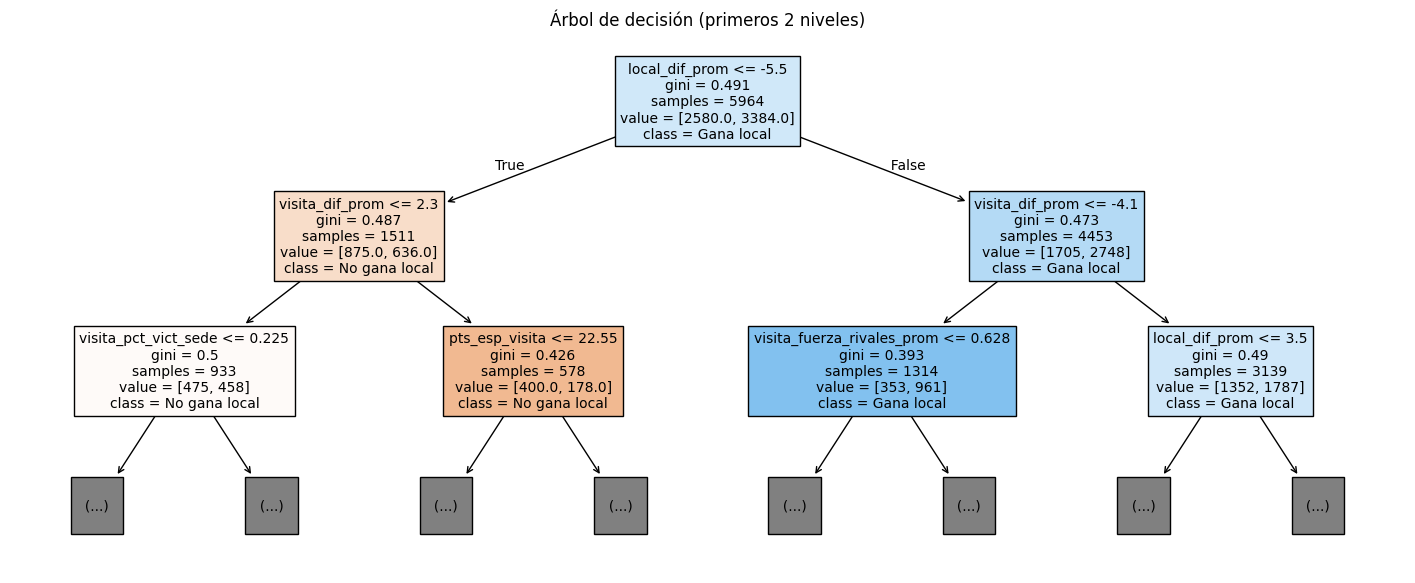

In [16]:
# Celda 16: árbol de decisión (entrenar, evaluar y graficar)
arbol = DecisionTreeClassifier(max_depth=4, min_samples_leaf=50, random_state=42)
arbol.fit(X_train, y_train)

acc_arbol_train = accuracy_score(y_train, arbol.predict(X_train))
acc_arbol_test  = accuracy_score(y_test,  arbol.predict(X_test))
print(f"Exactitud entrenamiento: {acc_arbol_train:.1%}")
print(f"Exactitud prueba:        {acc_arbol_test:.1%}")

# Graficamos solo los 2 primeros niveles para que sea legible
plt.figure(figsize=(18, 7))
plot_tree(arbol, feature_names=variables, class_names=["No gana local", "Gana local"],
          filled=True, max_depth=2, fontsize=10)
plt.title("Árbol de decisión (primeros 2 niveles)")
plt.savefig("../outputs/arbol_decision.png", dpi=150, bbox_inches="tight")
plt.show()

### Comparación inicial

Tabla resumen de la exactitud en el conjunto de prueba frente a la línea base.

In [17]:
# Celda 17: tabla comparativa inicial
resultados = pd.DataFrame({
    "Modelo": ["Línea base", "Regresión logística", "Árbol de decisión"],
    "Exactitud entrenamiento": [None, acc_logit_train, acc_arbol_train],
    "Exactitud prueba": [acc_base, acc_logit_test, acc_arbol_test],
})
resultados["Mejora vs base (puntos)"] = (resultados["Exactitud prueba"] - acc_base) * 100
resultados.round(3)

,Modelo,Exactitud entrenamiento,Exactitud prueba,Mejora vs base (puntos)
0,Línea base,NaN,0.545,0.000
1,Regresión logística,0.635,0.621,7.656
2,Árbol de decisión,0.631,0.616,7.097


### Reglas del árbol en texto

Imprimimos las reglas del árbol como texto para leer con facilidad cada pregunta y su umbral. Cada nivel de sangría es un nivel más de profundidad.

In [18]:
# Celda 18: reglas del árbol en formato de texto
from sklearn.tree import export_text

print(export_text(arbol, feature_names=variables, max_depth=2))

|--- local_dif_prom <= -5.50
|   |--- visita_dif_prom <= 2.30
|   |   |--- visita_pct_vict_sede <= 0.23
|   |   |   |--- truncated branch of depth 2
|   |   |--- visita_pct_vict_sede >  0.23
|   |   |   |--- truncated branch of depth 2
|   |--- visita_dif_prom >  2.30
|   |   |--- pts_esp_visita <= 22.55
|   |   |   |--- class: 0
|   |   |--- pts_esp_visita >  22.55
|   |   |   |--- truncated branch of depth 2
|--- local_dif_prom >  -5.50
|   |--- visita_dif_prom <= -4.10
|   |   |--- visita_fuerza_rivales_prom <= 0.63
|   |   |   |--- truncated branch of depth 2
|   |   |--- visita_fuerza_rivales_prom >  0.63
|   |   |   |--- truncated branch of depth 2
|   |--- visita_dif_prom >  -4.10
|   |   |--- local_dif_prom <= 3.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- local_dif_prom >  3.50
|   |   |   |--- truncated branch of depth 2



## 7. Evaluación del modelo

### Reporte de clasificación

Calculamos precisión, recall y F1 para cada clase, en ambos modelos:
- **Precisión:** de las predicciones de una clase, qué porcentaje fue correcto.
- **Recall:** de los casos reales de una clase, qué porcentaje detectó el modelo.
- **F1:** media armónica de precisión y recall.

`macro avg` promedia las dos clases por igual, sin importar cuántos casos tenga cada una. Es útil cuando las clases no están balanceadas.

In [19]:
# Celda 19: precisión, recall y F1 por clase
from sklearn.metrics import classification_report

nombres = ["No gana local", "Gana local"]

print("=== Regresión logística ===")
print(classification_report(y_test, logit.predict(X_test), target_names=nombres, digits=3))

print("=== Árbol de decisión ===")
print(classification_report(y_test, arbol.predict(X_test), target_names=nombres, digits=3))

=== Regresión logística ===
               precision    recall  f1-score   support

No gana local      0.615     0.450     0.520       571
   Gana local      0.624     0.764     0.687       683

     accuracy                          0.621      1254
    macro avg      0.620     0.607     0.604      1254
 weighted avg      0.620     0.621     0.611      1254

=== Árbol de decisión ===
               precision    recall  f1-score   support

No gana local      0.614     0.420     0.499       571
   Gana local      0.616     0.779     0.688       683

     accuracy                          0.616      1254
    macro avg      0.615     0.600     0.594      1254
 weighted avg      0.615     0.616     0.602      1254



### Matrices de confusión

Comparamos visualmente los aciertos y los errores de cada modelo. La diagonal son los aciertos; fuera de la diagonal están los dos tipos de error.

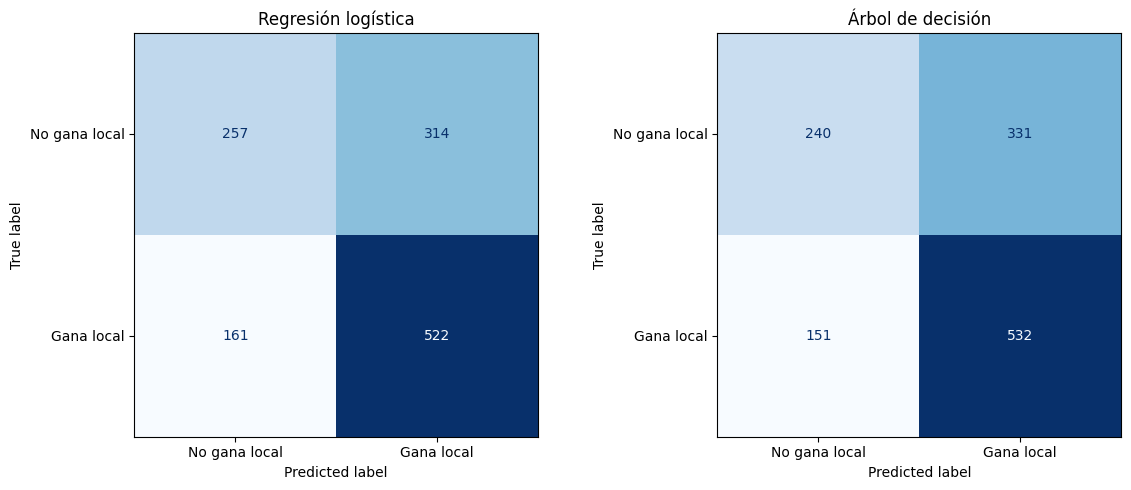

In [20]:
# Celda 20: matrices de confusión lado a lado
from sklearn.metrics import ConfusionMatrixDisplay

fig, ejes = plt.subplots(1, 2, figsize=(12, 5))

for eje, (nombre, mod) in zip(ejes, [("Regresión logística", logit), ("Árbol de decisión", arbol)]):
    ConfusionMatrixDisplay.from_estimator(
        mod, X_test, y_test, display_labels=nombres, cmap="Blues", ax=eje, colorbar=False
    )
    eje.set_title(nombre)

plt.tight_layout()
plt.savefig("../outputs/matrices_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Optimización del modelo

### Modelo 3: Random Forest

Entrena muchos árboles de decisión, cada uno con una muestra distinta de los datos y de las variables, y combina sus votos. Esto reduce el sobreajuste de un árbol individual y suele mejorar la estabilidad de las predicciones.

In [21]:
# Celda 21: Random Forest con parámetros iniciales
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=30,
                            random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

print(f"Exactitud entrenamiento: {accuracy_score(y_train, rf.predict(X_train)):.1%}")
print(f"Exactitud prueba:        {accuracy_score(y_test,  rf.predict(X_test)):.1%}")

Exactitud entrenamiento: 66.3%
Exactitud prueba:        62.6%


### Ajuste de hiperparámetros con validación cruzada temporal

Los **hiperparámetros** son configuraciones que elegimos nosotros y que el modelo no aprende solo (profundidad del árbol, fuerza de regularización, etc.). Para encontrar los mejores usamos `GridSearchCV`, que prueba todas las combinaciones de una lista.

Cada combinación se evalúa con **validación cruzada temporal** (`TimeSeriesSplit`): el conjunto de entrenamiento se divide en 5 bloques cronológicos y siempre se entrena con el pasado para validar con el bloque siguiente. Así nunca usamos el futuro para predecir el pasado.

- Métrica de selección: **F1 macro**, que pesa por igual ambas clases, para no premiar a un modelo que siempre predice "gana local".
- `class_weight="balanced"` da más peso a la clase minoritaria (no gana local) durante el entrenamiento.
- `C` en la regresión logística controla la regularización: valores pequeños obligan a un modelo más simple.

El conjunto de prueba (2022 en adelante) no se toca en esta etapa.

In [22]:
# Celda 22: búsqueda de hiperparámetros con validación cruzada temporal
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

cv_tiempo = TimeSeriesSplit(n_splits=5)  # 5 bloques cronológicos dentro de entrenamiento

# Regresión logística
grid_logit = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    param_grid={
        "logisticregression__C": [0.01, 0.1, 1, 10],
        "logisticregression__class_weight": [None, "balanced"],
    },
    cv=cv_tiempo, scoring="f1_macro", n_jobs=-1,
)
grid_logit.fit(X_train, y_train)
print("Logística - mejores parámetros:", grid_logit.best_params_)
print(f"Logística - F1 macro en validación: {grid_logit.best_score_:.3f}")

# Random Forest (puede tardar 1 a 3 minutos)
grid_rf = GridSearchCV(
    RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=1),
    param_grid={
        "max_depth": [4, 6, 8],
        "min_samples_leaf": [20, 50],
        "class_weight": [None, "balanced"],
    },
    cv=cv_tiempo, scoring="f1_macro", n_jobs=-1,
)
grid_rf.fit(X_train, y_train)
print("\nRandom Forest - mejores parámetros:", grid_rf.best_params_)
print(f"Random Forest - F1 macro en validación: {grid_rf.best_score_:.3f}")

Logística - mejores parámetros: {'logisticregression__C': 0.01, 'logisticregression__class_weight': 'balanced'}
Logística - F1 macro en validación: 0.619

Random Forest - mejores parámetros: {'class_weight': 'balanced', 'max_depth': 6, 'min_samples_leaf': 50}
Random Forest - F1 macro en validación: 0.612


### Comparación final de modelos

Evaluamos todos los modelos en el conjunto de prueba con las mismas métricas. Usamos el promedio macro (ambas clases pesan igual) para precisión, recall y F1.

In [23]:
# Celda 23: tabla comparativa final en el conjunto de prueba
from sklearn.metrics import precision_score, recall_score, f1_score

def evaluar(nombre, mod):
    """Calcula las métricas de un modelo sobre el conjunto de prueba."""
    pred = mod.predict(X_test)
    return {
        "Modelo": nombre,
        "Exactitud": accuracy_score(y_test, pred),
        "Precisión (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, pred, average="macro"),
        "F1 (macro)": f1_score(y_test, pred, average="macro"),
    }

modelos = [
    ("Línea base", base),
    ("Regresión logística", logit),
    ("Árbol de decisión", arbol),
    ("Random Forest", rf),
    ("Logística optimizada", grid_logit.best_estimator_),
    ("Random Forest optimizado", grid_rf.best_estimator_),
]
tabla = pd.DataFrame([evaluar(n, m) for n, m in modelos]).round(3)
tabla.to_csv("../outputs/tabla_comparativa.csv", index=False)
tabla

,Modelo,Exactitud,Precisión (macro),Recall (macro),F1 (macro)
0,Línea base,0.545,0.272,0.500,0.353
1,Regresión logística,0.621,0.620,0.607,0.604
2,Árbol de decisión,0.616,0.615,0.600,0.594
3,Random Forest,0.626,0.628,0.610,0.604
4,Logística optimizada,0.636,0.634,0.635,0.634
5,Random Forest optimizado,0.618,0.616,0.617,0.616


### Gráfica comparativa

Comparación visual de exactitud y F1 macro de cada modelo frente a la línea base (línea punteada).

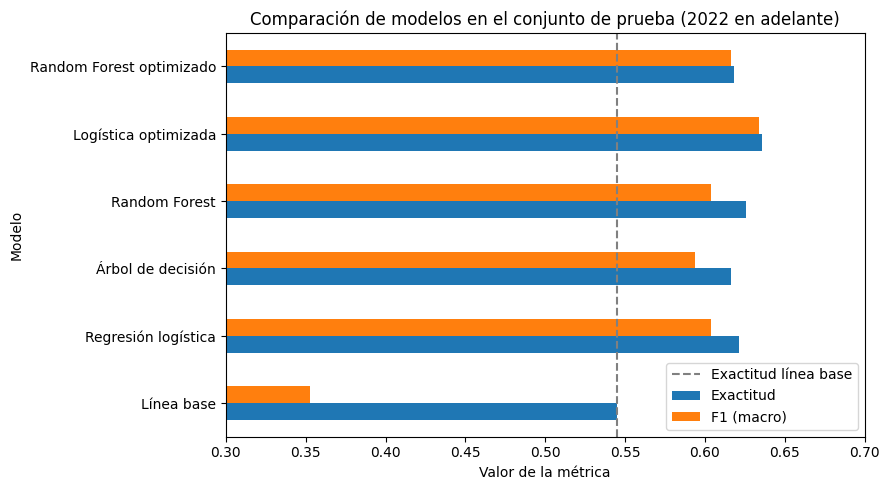

In [24]:
# Celda 24: gráfica comparativa de modelos
ax = tabla.set_index("Modelo")[["Exactitud", "F1 (macro)"]].plot.barh(figsize=(9, 5))
ax.axvline(acc_base, color="gray", linestyle="--", label="Exactitud línea base")
ax.set_xlim(0.3, 0.7)
ax.set_xlabel("Valor de la métrica")
ax.set_title("Comparación de modelos en el conjunto de prueba (2022 en adelante)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../outputs/comparacion_modelos.png", dpi=150, bbox_inches="tight")
plt.show()

### Importancia de variables (Random Forest optimizado)

Muestra cuánto contribuye cada variable a las decisiones del Random Forest. Sirve para explicar qué factores pesan más en la predicción del resultado.

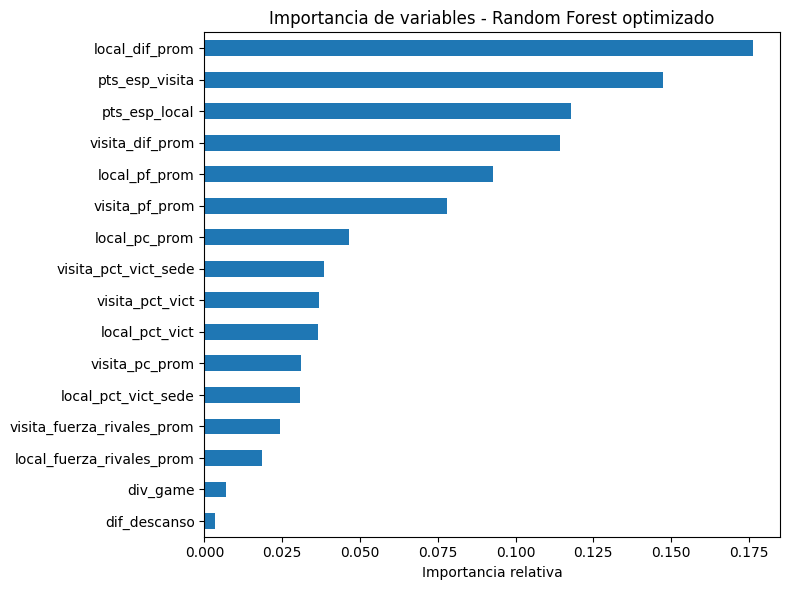

In [25]:
# Celda 25: importancia de variables
importancias = pd.Series(grid_rf.best_estimator_.feature_importances_, index=variables).sort_values()

ax = importancias.plot.barh(figsize=(8, 6))
ax.set_xlabel("Importancia relativa")
ax.set_title("Importancia de variables - Random Forest optimizado")
plt.tight_layout()
plt.savefig("../outputs/importancia_variables.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Predicciones para el Data Warehouse

Guardamos las predicciones del mejor modelo sobre el conjunto de prueba, con la probabilidad de victoria del local. Este archivo tiene la estructura de una posible tabla de hechos `HechoPrediccion`, ligada a `DimEquipo` (local y visitante), `DimFecha` y `DimTemporada` mediante sus claves.

In [26]:
# Celda 26: exportar predicciones del mejor modelo
mejor = grid_logit.best_estimator_  # cambia a grid_rf.best_estimator_ si obtuvo mejor F1 en la Celda 23

predicciones = test[["game_id", "season", "week", "gameday", "home_team", "away_team"]].copy()
predicciones["prob_gana_local"] = mejor.predict_proba(X_test)[:, 1].round(3)
predicciones["prediccion"] = mejor.predict(X_test)
predicciones["real"] = y_test.values
predicciones["acierto"] = (predicciones["prediccion"] == predicciones["real"]).astype(int)

predicciones.to_csv("../outputs/predicciones_test.csv", index=False)
predicciones.head()

,game_id,season,week,gameday,home_team,away_team,prob_gana_local,prediccion,real,acierto
5964,2022_01_BUF_LA,2022,1,2022-09-08,LA,BUF,0.450,0,0,1
5965,2022_01_PHI_DET,2022,1,2022-09-11,DET,PHI,0.421,0,0,1
5966,2022_01_PIT_CIN,2022,1,2022-09-11,CIN,PIT,0.586,1,0,0
5967,2022_01_IND_HOU,2022,1,2022-09-11,HOU,IND,0.344,0,0,1
5968,2022_01_CLE_CAR,2022,1,2022-09-11,CAR,CLE,0.333,0,0,1


## 10. Regresión complementaria: diferencia de puntos

Usamos las mismas variables de entrada y la misma partición por fecha, pero ahora la variable objetivo es numérica: la diferencia de puntos del partido (puntos del local menos los del visitante).

- **Línea base:** siempre predice la diferencia promedio del entrenamiento.
- **Regresión lineal:** el modelo de regresión más simple e interpretable.
- **Random Forest de regresión:** puede captar relaciones no lineales.

Métricas: **MAE** (error promedio en puntos), **RMSE** (castiga más los errores grandes) y **R²** (proporción de la variación que explica el modelo).

In [27]:
# Celda 27: regresión complementaria (predecir la diferencia de puntos)
import numpy as np
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Misma partición, nueva variable objetivo (numérica)
y_train_r = train["diferencial"]
y_test_r  = test["diferencial"]

modelos_r = [
    ("Línea base (promedio)", DummyRegressor(strategy="mean")),
    ("Regresión lineal", make_pipeline(StandardScaler(), LinearRegression())),
    ("Random Forest de regresión", RandomForestRegressor(n_estimators=300, max_depth=6,
                                                         min_samples_leaf=50, random_state=42, n_jobs=-1)),
]

filas = []
for nombre, mod in modelos_r:
    mod.fit(X_train, y_train_r)
    pred = mod.predict(X_test)
    filas.append({
        "Modelo": nombre,
        "MAE": mean_absolute_error(y_test_r, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test_r, pred)),
        "R²": r2_score(y_test_r, pred),
    })

tabla_r = pd.DataFrame(filas).round(3)
tabla_r.to_csv("../outputs/tabla_regresion.csv", index=False)
tabla_r

,Modelo,MAE,RMSE,R²
0,Línea base (promedio),10.780,13.900,-0.001
1,Regresión lineal,10.071,13.061,0.117
2,Random Forest de regresión,10.118,13.091,0.113
